# `gpl_signal` on the first 10 seconds

Read the default LeiData WAV, scale it the way `read_wav_mono` does, then run the STFT and the noise whitener. The histograms and the spectrogram are those first 10 seconds. The spectrogram is the whitened STFT from 10 Hz to 10 kHz, shown with the cube-root display transform.

In [1]:
import sys
import wave
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "analysis" / "GPL_Python" / "gpl_signal.py").is_file():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break

from analysis.GPL_Python.decimate_wav import DEFAULT_WAV
from analysis.GPL_Python.gpl_signal import (
    DetectorParams,
    STFTProcessor,
    WhiteningProcessor,
    integer_wav_scale,
    slice_gpl_freq_band,
)

SECONDS = 10
with wave.open(str(DEFAULT_WAV)) as handle:
    sample_rate = handle.getframerate()
    channels = handle.getnchannels()
    width = handle.getsampwidth()
    raw = handle.readframes(SECONDS * sample_rate)

pcm = np.frombuffer(raw, dtype=np.dtype(f"<i{width}"))
if channels > 1:
    pcm = pcm.reshape(-1, channels)[:, 0]
samples = pcm.astype(np.float64) / integer_wav_scale(np.dtype(f"<i{width}"))

parm = DetectorParams.for_audio(sample_rate, len(samples)).with_window_samples(len(samples))
spectrum = slice_gpl_freq_band(STFTProcessor().compute(samples, parm), parm.freq_bin_lo, parm.freq_bin_hi)
whitened = WhiteningProcessor().apply(spectrum, parm)

duration = len(samples) / sample_rate
print(f"{DEFAULT_WAV.name}  {sample_rate} Hz  {duration:.1f} s  {len(samples)} samples")
print(
    f"STFT {parm.fftl}  hop {parm.fft_overlap} samples  "
    f"whitened {whitened.shape[0]} bins x {whitened.shape[1]} frames  "
    f"{parm.freq_lo:.0f}-{parm.freq_hi:.0f} Hz"
)

SOCAL_H_76_230427_014845.x.wav  200000 Hz  10.0 s  2000000 samples
STFT 32768  hop 24576 samples  whitened 1637 bins x 80 frames  10-10000 Hz


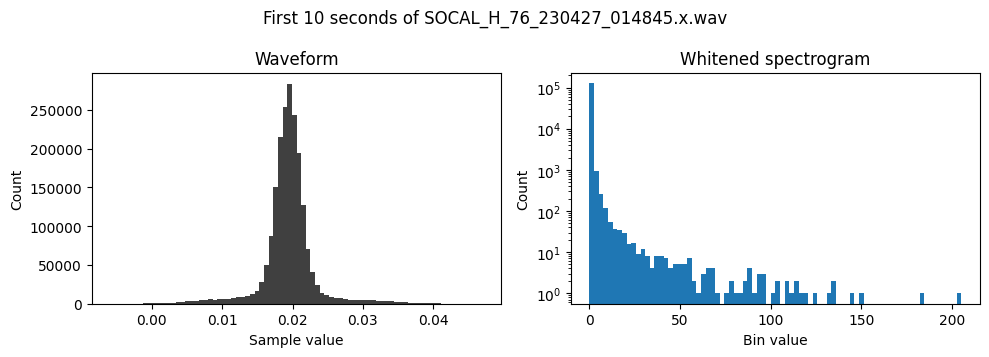

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

axes[0].hist(samples, bins=80, color="0.25")
axes[0].set_title("Waveform")
axes[0].set_xlabel("Sample value")
axes[0].set_ylabel("Count")

axes[1].hist(whitened.ravel(), bins=80, color="C0")
axes[1].set_yscale("log")
axes[1].set_title("Whitened spectrogram")
axes[1].set_xlabel("Bin value")
axes[1].set_ylabel("Count")

fig.suptitle(f"First {duration:.0f} seconds of {DEFAULT_WAV.name}")
fig.tight_layout()
plt.show()

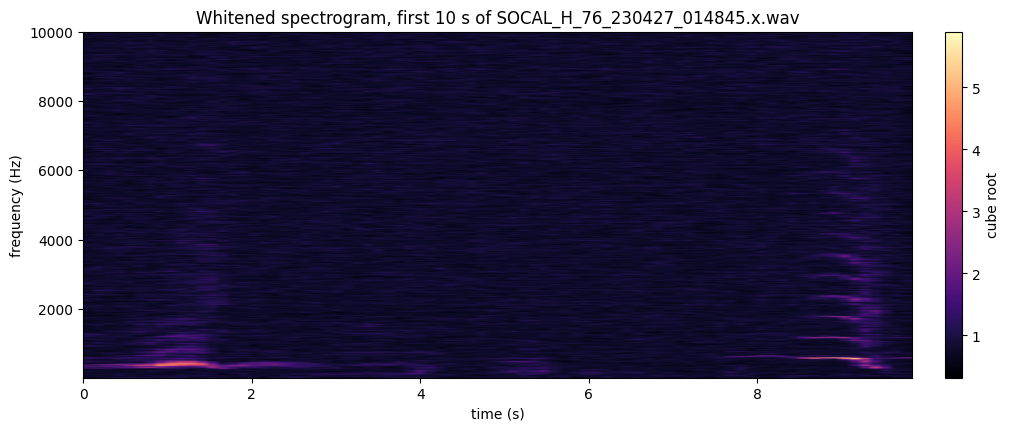

In [3]:
from analysis.GPL_Python.gpl_outputs import display_from_spwhiten

hop_s = parm.fft_overlap / sample_rate
n_frames = whitened.shape[1]
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
image = ax.imshow(
    display_from_spwhiten(whitened),
    origin="lower",
    aspect="auto",
    cmap="magma",
    extent=[0, n_frames * hop_s, parm.freq_lo, parm.freq_hi],
)
ax.set_xlabel("time (s)")
ax.set_ylabel("frequency (Hz)")
ax.set_title(f"Whitened spectrogram, first {duration:.0f} s of {DEFAULT_WAV.name}")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="cube root")
plt.show()